<a href="https://colab.research.google.com/github/2007Mateo/Aprendizaje_Autom-tico_Inicial_GV/blob/main/06-SVM_Resuelto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Máquinas de soporte vectorial
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Andrés Merino &bull; Periodo 2026-2
            </font></p>
        </td>  
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

A lo largo de este taller, aplicaremos el algoritmo de máquinas de soporte vectorial (SVM) para clasificar un conjunto de datos.

**Repositorio del estudiante:** `2007Mateo`  
**Caso de estudio:** productividad de equipos de costura (`Dep2.csv`).

**Referencia didáctica:** [11-SVM.ipynb — Andrés Merino](https://github.com/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Notebooks/11-SVM.ipynb). Se adaptan sus regiones de decisión, vectores de soporte y comparaciones de kernels a los registros reales de costura, sin generar datos sintéticos ni usar Pokémon.

Los paquetes necesarios son:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, balanced_accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone

SEMILLA = 42

---
## <font color='264CC7'> Clasificación </font>


### <font color='264CC7'> Preprocesamiento de datos </font>

Primero necesitas el conjunto de datos. Usa el conjunto de datos seleccionado en las primeras semanas.

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Carga el conjunto de datos y procésalos:
<ul>
  <li>Muestra algunos datos.</li>
  <li>Muestra una descripción de los datos.</li>
  <li>Define predictores y objetivo, excluyendo información que revele la respuesta.</li>
  <li>Reserva prueba y divide el resto en entrenamiento y validación con semillas registradas; estratifica si se trata de clasificación y los tamaños de clase lo permiten.</li>
  <li>Ajusta imputación, codificación y escalado solo con entrenamiento; transforma validación sin reajustar.</li>
</ul>
</div>

In [2]:
# Fuente original: repositorio personal de la asignatura.
url = "https://raw.githubusercontent.com/2007Mateo/Aprendizaje_Autom-tico_Inicial_GV/main/Dep2.csv"
data = pd.read_csv(url, sep=";").dropna(how="all")
data = data.loc[data["department"].eq("sewing")].copy()

# Solo se eliminan filas sin información suficiente para construir la etiqueta.
for col in ["targeted_productivity", "actual_productivity"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")
antes = len(data)
data = data.dropna(subset=["targeted_productivity", "actual_productivity"]).reset_index(drop=True)
print(f"Registros de costura: {antes}; con etiqueta válida: {len(data)}")

# 1 = cumple o supera la meta; 0 = no cumple la meta.
y = (data["actual_productivity"] >= data["targeted_productivity"]).astype(int).rename("cumple_meta")

# La productividad real solo se usa para construir y, nunca como predictor.
# Se excluye incentive porque podría depender del resultado obtenido.
# over_time se usa como característica operativa registrada (en una predicción
# anticipada habría que verificar que se conoce antes de medir productividad).
numeric_cols = ["targeted_productivity", "smv", "over_time", "no_of_workers"]
X = data[numeric_cols].apply(pd.to_numeric, errors="coerce")

# Separación estratificada: 60% entrenamiento, 20% validación, 20% prueba.
# El segundo split toma el 25% del 80% restante.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=SEMILLA, stratify=y_dev)
assert not set(X_train.index) & set(X_val.index)
assert not set(X_train.index) & set(X_test.index)
assert not set(X_val.index) & set(X_test.index)
assert "actual_productivity" not in X.columns and "incentive" not in X.columns

# Exploración de predictores y distribuciones SOLO en entrenamiento.
print("Ejemplos de entrenamiento:")
display(X_train.join(y_train).head())
print("Descripción de predictores (entrenamiento):")
display(X_train.describe().round(2))
print("Faltantes (entrenamiento):")
display(X_train.isna().sum())
print("Tamaños de las particiones:")
display(pd.Series({"Entrenamiento": len(X_train), "Validación": len(X_val),
                   "Prueba reservada": len(X_test)}).to_frame("n"))
print("Distribución de clases en entrenamiento y validación:")
display(pd.DataFrame({"Entrenamiento": y_train.value_counts(),
                      "Validación": y_val.value_counts()}).sort_index())

# Las transformaciones se ajustan dentro del pipeline, solo con entrenamiento.
# No hace falta codificación categórica: los cuatro predictores son numéricos.
def pipeline(modelo):
    return Pipeline([("imputacion", SimpleImputer(strategy="median")),
                     ("escalado", StandardScaler()), ("modelo", modelo)])

Registros de costura: 691; con etiqueta válida: 691
Ejemplos de entrenamiento:


,targeted_productivity,smv,over_time,no_of_workers,cumple_meta
13,0.8,28.08,6540,54.5,1
513,0.7,30.10,8160,58.0,0
662,0.7,21.82,6000,50.0,1
669,0.8,15.26,4080,34.0,1
581,0.6,27.48,6720,56.0,1


Descripción de predictores (entrenamiento):


,targeted_productivity,smv,over_time,no_of_workers
count,414.00,414.00,414.00,414.00
mean,0.73,23.12,6535.83,51.97
std,0.10,6.91,2975.18,9.62
min,0.07,10.05,0.00,26.00
25%,0.70,18.79,4275.00,52.00
50%,0.75,22.52,6840.00,56.50
75%,0.80,27.48,8205.00,58.00
max,0.80,54.56,25920.00,60.00


Faltantes (entrenamiento):


targeted_productivity    0
smv                      0
over_time                0
no_of_workers            0
dtype: int64

Tamaños de las particiones:


,n
Entrenamiento,414
Validación,138
Prueba reservada,139


Distribución de clases en entrenamiento y validación:


,Entrenamiento,Validación
cumple_meta,,
0,85,29
1,329,109


---
## <font color='264CC7'> Ejemplo con nuestros datos: regiones de decisión </font>

En el cuaderno 11-SVM, el profesor representa observaciones de dos dimensiones, regiones de decisión y vectores de soporte. Nuestra base tiene cuatro predictores, por lo que usamos PCA para proyectarlos a dos componentes, ajustando imputación, escalado y PCA únicamente con entrenamiento. Los SVM de esta sección se entrenan sobre esas dos componentes: ilustran fronteras **reales en 2D**, pero no son el modelo principal de cuatro variables. Las clases son 0 (no cumple) y 1 (cumple la meta). No usamos prueba para estas figuras.

Varianza explicada: PC1=46.40%; PC2=25.71%; total=72.11%


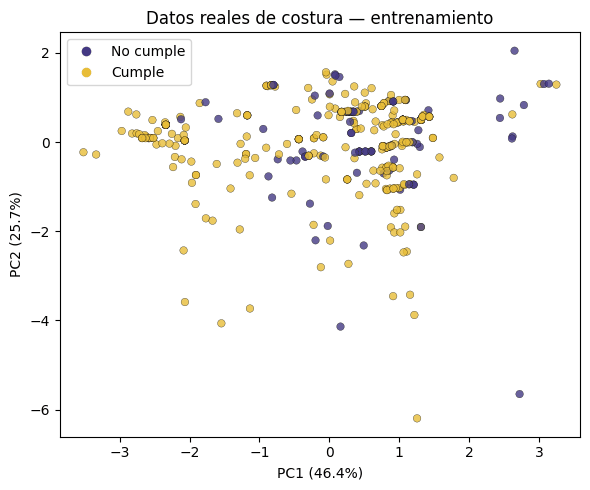

In [3]:
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

# Preparar una vista bidimensional sin usar validación ni prueba en el ajuste.
preparacion_2d = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("pca", PCA(n_components=2))
])
X_train_2d = preparacion_2d.fit_transform(X_train)
X_val_2d = preparacion_2d.transform(X_val)
var = preparacion_2d.named_steps["pca"].explained_variance_ratio_
print(f"Varianza explicada: PC1={var[0]:.2%}; PC2={var[1]:.2%}; total={var.sum():.2%}")
colores = ListedColormap(["#443983", "#e8bd38"])
fondo = ListedColormap(["#d2c9e6", "#fff0a6"])

def ejes_2d(ax):
    ax.set_xlabel(f"PC1 ({var[0]:.1%})")
    ax.set_ylabel(f"PC2 ({var[1]:.1%})")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train,
           cmap=colores, vmin=0, vmax=1, s=30, edgecolor="k", linewidth=.25, alpha=.8)
ejes_2d(ax)
ax.set_title("Datos reales de costura — entrenamiento")
ax.legend(handles=[Line2D([0],[0], marker="o", color="w", markerfacecolor=colores(i),
                          label=nombre, markersize=8) for i,nombre in enumerate(["No cumple", "Cumple"])])
plt.tight_layout(); plt.show()


### <font color='264CC7'> SVM lineal y RBF: exactitud, matriz de confusión y regiones </font>

Como en el ejemplo del profesor, comparamos primero un kernel lineal y luego RBF. Los círculos vacíos identifican los vectores de soporte. La línea negra, cuando existe dentro de la ventana, señala la frontera; las líneas discontinuas señalan los niveles de decisión −1 y +1 cuando están presentes. Una región de un solo color puede ser un resultado real del desbalance de clases, no un error de dibujo.


Kernel Lineal — validación
Exactitud: 0.7899
Matriz de confusión:
[[  0  29]
 [  0 109]]
              precision    recall  f1-score   support

   No cumple       0.00      0.00      0.00        29
      Cumple       0.79      1.00      0.88       109

    accuracy                           0.79       138
   macro avg       0.39      0.50      0.44       138
weighted avg       0.62      0.79      0.70       138



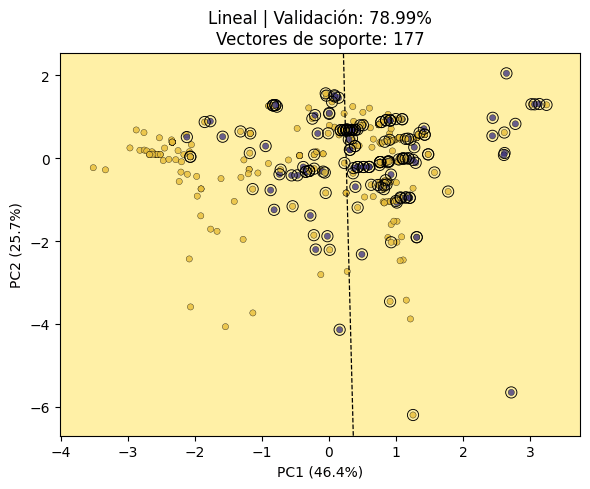


Kernel RBF — validación
Exactitud: 0.8043
Matriz de confusión:
[[  2  27]
 [  0 109]]
              precision    recall  f1-score   support

   No cumple       1.00      0.07      0.13        29
      Cumple       0.80      1.00      0.89       109

    accuracy                           0.80       138
   macro avg       0.90      0.53      0.51       138
weighted avg       0.84      0.80      0.73       138



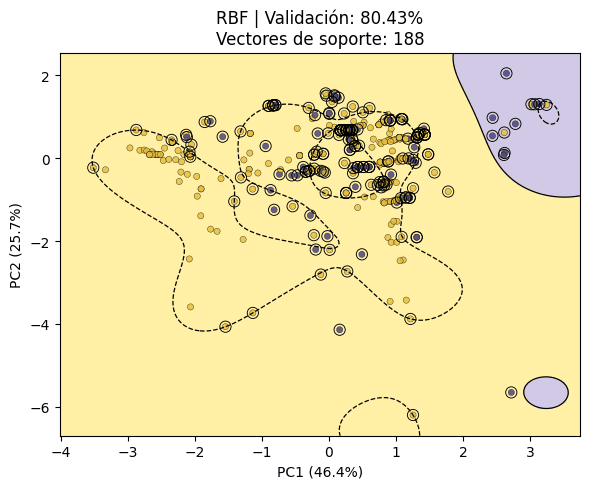

In [4]:
# Malla común para que las regiones sean comparables.
lim_inf = X_train_2d.min(axis=0) - .5
lim_sup = X_train_2d.max(axis=0) + .5
xx, yy = np.meshgrid(np.linspace(lim_inf[0], lim_sup[0], 220),
                     np.linspace(lim_inf[1], lim_sup[1], 220))
malla = np.c_[xx.ravel(), yy.ravel()]

def dibujar_region(ax, modelo, titulo):
    Z = modelo.predict(malla).reshape(xx.shape)
    scores = modelo.decision_function(malla).reshape(xx.shape)
    ax.pcolormesh(xx, yy, Z, cmap=fondo, shading="auto", vmin=0, vmax=1)
    niveles = [v for v in [-1, 0, 1] if scores.min() < v < scores.max()]
    if niveles:
        ax.contour(xx, yy, scores, levels=niveles, colors="k",
                   linestyles=["solid" if v == 0 else "dashed" for v in niveles], linewidths=.9)
    ax.scatter(X_train_2d[:,0], X_train_2d[:,1], c=y_train, cmap=colores,
               vmin=0, vmax=1, s=20, edgecolor="k", linewidth=.3, alpha=.8)
    sv = modelo.support_vectors_
    ax.scatter(sv[:,0], sv[:,1], s=65, facecolors="none", edgecolors="k", linewidths=.65)
    ax.set(xlim=(lim_inf[0],lim_sup[0]), ylim=(lim_inf[1],lim_sup[1]))
    ejes_2d(ax)
    ax.set_title(f"{titulo} | Validación: {modelo.score(X_val_2d,y_val):.2%}\nVectores de soporte: {len(sv)}")

modelos_2d = {}
for nombre, params in [("Lineal", {"kernel":"linear"}), ("RBF", {"kernel":"rbf"})]:
    modelo_2d = SVC(C=1, **params).fit(X_train_2d, y_train)
    modelos_2d[nombre] = modelo_2d
    pred = modelo_2d.predict(X_val_2d)
    print(f"\nKernel {nombre} — validación")
    print(f"Exactitud: {accuracy_score(y_val,pred):.4f}")
    print("Matriz de confusión:", confusion_matrix(y_val,pred,labels=[0,1]), sep="\n")
    print(classification_report(y_val,pred,labels=[0,1],target_names=["No cumple","Cumple"],zero_division=0))
    fig, ax = plt.subplots(figsize=(6,5))
    dibujar_region(ax, modelo_2d, nombre)
    plt.tight_layout(); plt.show()


### <font color='264CC7'> Kernels polinómicos y sigmoide </font>

Se mantienen las mismas particiones y ejes. Se comparan grados 2 y 3, tal como pide el cuaderno 11-SVM, y se incluye sigmoide como contraste exploratorio.

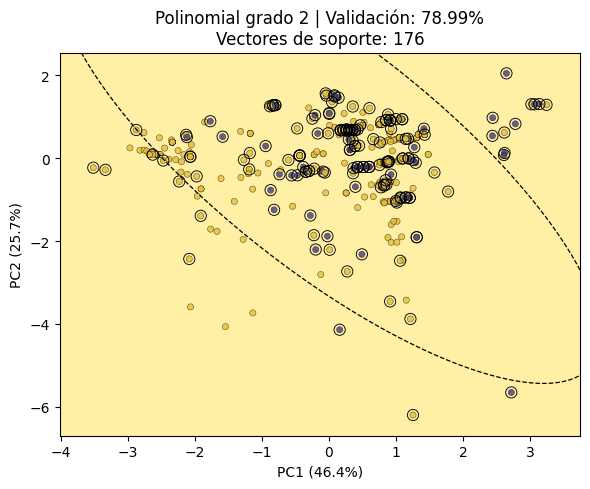

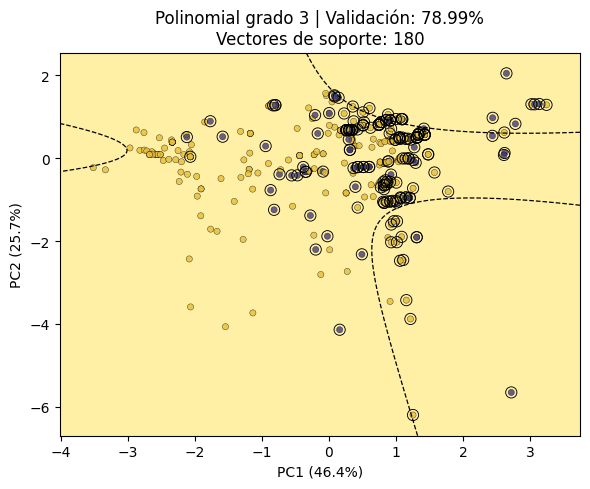

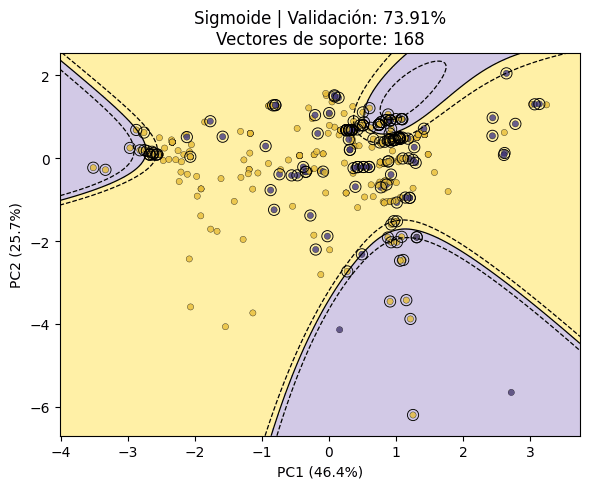

,Kernel,Entrenamiento,Validación,Vectores de soporte
0,Lineal,0.7947,0.7899,177
1,RBF,0.8068,0.8043,188
2,Polinomial grado 2,0.7947,0.7899,176
3,Polinomial grado 3,0.7947,0.7899,180
4,Sigmoide,0.7295,0.7391,168


In [5]:
for nombre, params in [("Polinomial grado 2", {"kernel":"poly","degree":2}),
                       ("Polinomial grado 3", {"kernel":"poly","degree":3}),
                       ("Sigmoide", {"kernel":"sigmoid"})]:
    modelo_2d = SVC(C=1, **params).fit(X_train_2d,y_train)
    modelos_2d[nombre] = modelo_2d
    fig, ax = plt.subplots(figsize=(6,5))
    dibujar_region(ax, modelo_2d, nombre)
    plt.tight_layout(); plt.show()

resumen_2d = pd.DataFrame([{"Kernel":nombre, "Entrenamiento":m.score(X_train_2d,y_train),
    "Validación":m.score(X_val_2d,y_val), "Vectores de soporte":len(m.support_vectors_)}
    for nombre,m in modelos_2d.items()])
display(resumen_2d.round(4))


### <font color='264CC7'> Exactitud frente al grado del kernel polinómico </font>

Repetimos la comparación de grados con las dos componentes. Aumentar el grado no garantiza mayor capacidad de generalización. No se alteran artificialmente los registros reales para imitar `make_blobs`, `make_circles` o `make_moons`.

,grado,entrenamiento,validación
0,1,0.7947,0.7899
1,2,0.7947,0.7899
2,3,0.7947,0.7899
3,4,0.7971,0.7899
4,5,0.7995,0.8043
5,6,0.8019,0.7899


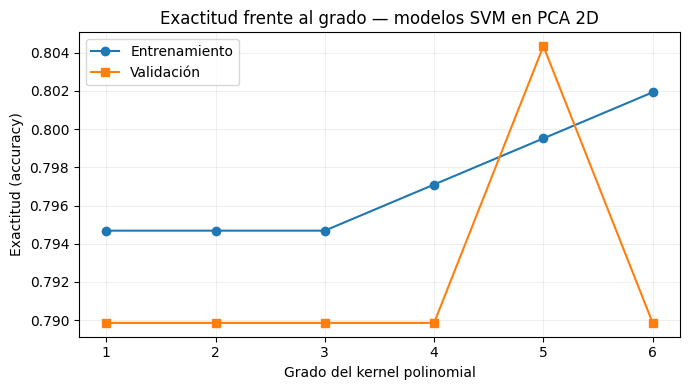

Mayor exactitud de validación en la comparación 2D: RBF


In [6]:
grados = range(1, 7)
resultados_grado = []
for grado in grados:
    m = SVC(kernel="poly", degree=grado, C=1).fit(X_train_2d,y_train)
    resultados_grado.append({"grado":grado, "entrenamiento":m.score(X_train_2d,y_train),
                             "validación":m.score(X_val_2d,y_val)})
tabla_grados = pd.DataFrame(resultados_grado)
display(tabla_grados.round(4))
plt.figure(figsize=(7,4))
plt.plot(tabla_grados.grado, tabla_grados.entrenamiento, marker="o", label="Entrenamiento")
plt.plot(tabla_grados.grado, tabla_grados["validación"], marker="s", label="Validación")
plt.xticks(list(grados)); plt.xlabel("Grado del kernel polinomial"); plt.ylabel("Exactitud (accuracy)")
plt.title("Exactitud frente al grado — modelos SVM en PCA 2D")
plt.legend(); plt.grid(alpha=.2); plt.tight_layout(); plt.show()
print("Mayor exactitud de validación en la comparación 2D:", resumen_2d.loc[resumen_2d.Validación.idxmax(),"Kernel"])


---
## <font color='264CC7'> Ejemplo práctico: modelo con las cuatro variables originales </font>

La evaluación principal continúa con los cuatro predictores, tal como en el ejemplo práctico multivariable del profesor. Las figuras anteriores son explicativas; las métricas siguientes corresponden al modelo completo.


### <font color='264CC7'> Determinación del mejor kernel </font>

In [7]:
# Configuraciones candidatas: mismas particiones para todas.
# C controla la penalización; gamma controla el alcance del kernel RBF.
valores_C = [0.01, 0.1, 1, 10, 100]
valores_gamma = ["scale", 0.01, 0.1, 1, 10]
configuraciones = []
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    for C in valores_C:
        for gamma in (valores_gamma if kernel == "rbf" else ["scale"]):
            configuraciones.append({"kernel": kernel, "C": C, "gamma": gamma})
print(f"Configuraciones SVM por evaluar: {len(configuraciones)}")

Configuraciones SVM por evaluar: 40


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Determina el mejor kernel para el modelo SVM.
<ul>
  <li>Genera una gráfica que muestre la exactitud (accuracy) de entrenamiento y validación con diferentes kernels.</li>
  <li>Compara también C y, para RBF, gamma sobre las mismas particiones.</li>
  <li>Selecciona la configuración por validación, sin consultar prueba.</li>
</ul>
</div>


,C,gamma,accuracy_train,accuracy_val,precision_val,recall_val,f1_val,balanced_accuracy_val
kernel,,,,,,,,
linear,0.01,scale,0.7947,0.7899,0.7899,1.0,0.8826,0.5000
poly,0.10,scale,0.8043,0.8043,0.8015,1.0,0.8898,0.5345
rbf,1.00,0.1,0.8068,0.8116,0.8074,1.0,0.8934,0.5517
sigmoid,0.01,scale,0.7947,0.7899,0.7899,1.0,0.8826,0.5000


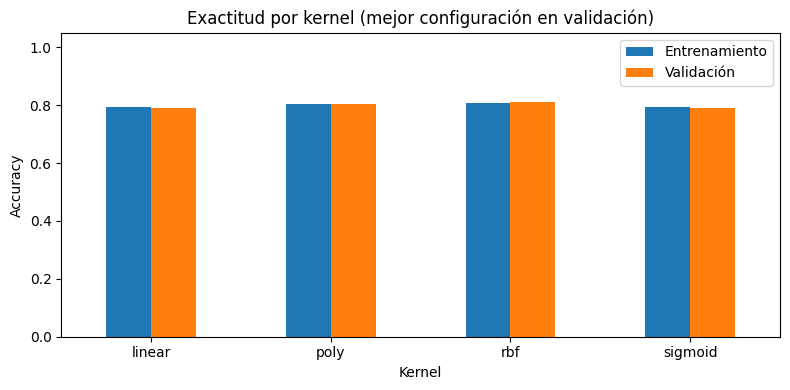

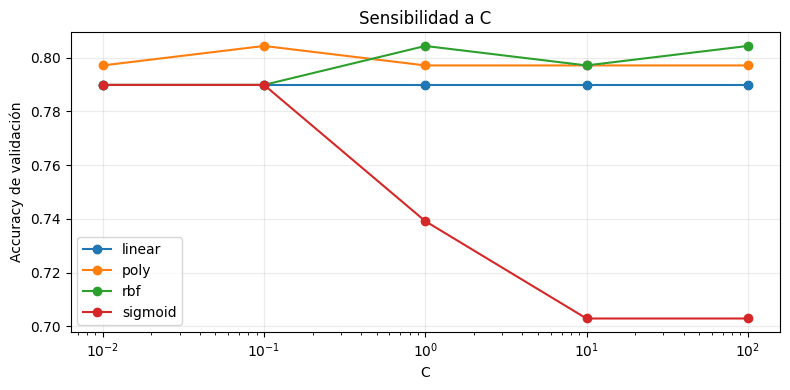

gamma,scale,0.01,0.1,1,10
C,,,,,
0.01,0.7899,0.7899,0.7899,0.7899,0.7899
0.10,0.7899,0.7899,0.7899,0.7899,0.7899
1.00,0.8043,0.7899,0.8116,0.7971,0.7971
10.00,0.7971,0.7899,0.8116,0.7826,0.8043
100.00,0.8043,0.8043,0.8043,0.7681,0.7754


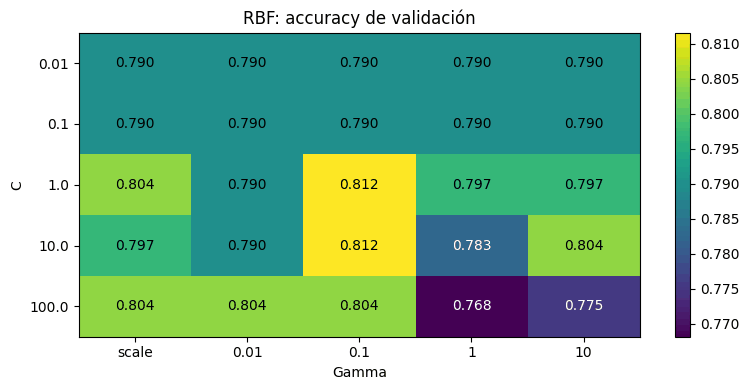

Mejor SVM por validación: {'kernel': 'rbf', 'C': 1.0, 'gamma': 0.1}
Accuracy entrenamiento: 0.8068; validación: 0.8116


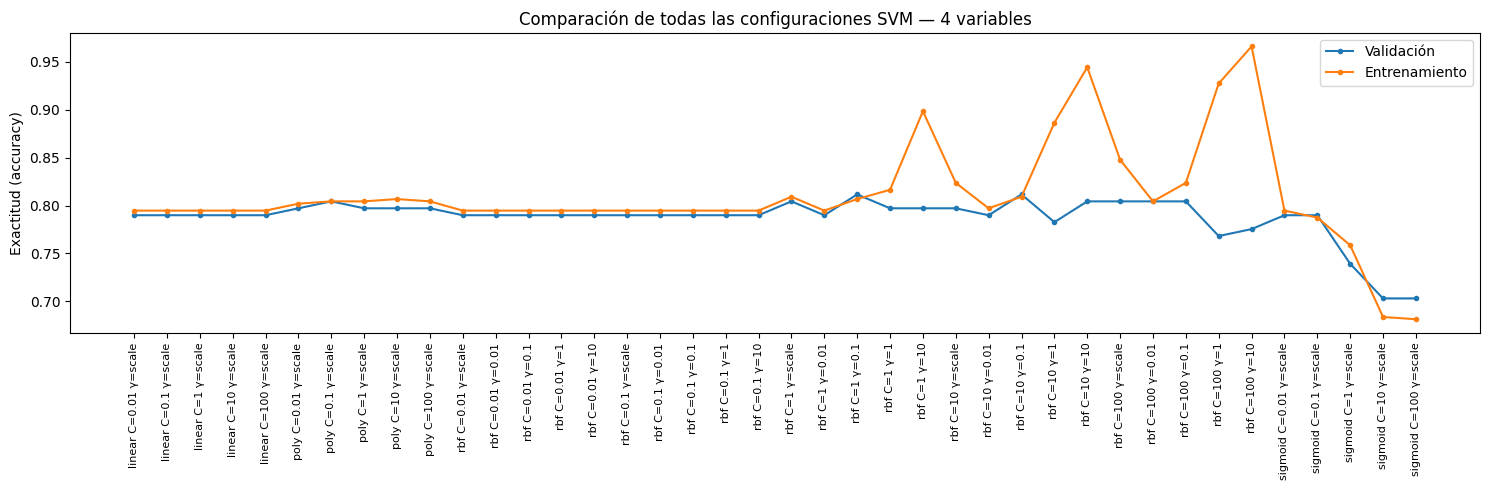

In [8]:
# Evaluar solo entrenamiento y validación. La prueba permanece reservada.
def metricas(y_real, y_pred):
    return {"accuracy": accuracy_score(y_real, y_pred),
            "precision": precision_score(y_real, y_pred, zero_division=0),
            "recall": recall_score(y_real, y_pred, zero_division=0),
            "f1": f1_score(y_real, y_pred, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_real, y_pred)}

resultados = []
for params in configuraciones:
    modelo = pipeline(SVC(**params, random_state=SEMILLA))
    modelo.fit(X_train, y_train)
    pred_train = modelo.predict(X_train)
    pred_val = modelo.predict(X_val)
    resultados.append({**params, "accuracy_train": accuracy_score(y_train, pred_train),
                       **{f"{k}_val": v for k,v in metricas(y_val, pred_val).items()}})
resultados = pd.DataFrame(resultados)
# Criterio fijado: accuracy de validación; empate: balanced accuracy y menor C.
orden = ["accuracy_val", "balanced_accuracy_val", "C"]
orden_asc = [False, False, True]
ranking = resultados.sort_values(orden, ascending=orden_asc, kind="stable")
mejor_svm = ranking.iloc[0]
mejores_kernel = ranking.drop_duplicates("kernel").set_index("kernel").loc[
    ["linear", "poly", "rbf", "sigmoid"]]
display(mejores_kernel.round(4))

ax = mejores_kernel[["accuracy_train", "accuracy_val"]].plot.bar(figsize=(8,4), rot=0)
ax.set(title="Exactitud por kernel (mejor configuración en validación)",
       ylabel="Accuracy", xlabel="Kernel", ylim=(0,1.05))
ax.legend(["Entrenamiento", "Validación"])
plt.tight_layout(); plt.show()

# Sensibilidad a C con gamma='scale' para comparar todos los kernels.
fig, ax = plt.subplots(figsize=(8,4))
for kernel, grupo in resultados[resultados.gamma.eq("scale")].groupby("kernel"):
    ax.plot(grupo.C, grupo.accuracy_val, marker="o", label=kernel)
ax.set(xscale="log", xlabel="C", ylabel="Accuracy de validación", title="Sensibilidad a C")
ax.legend(); ax.grid(alpha=.25); plt.tight_layout(); plt.show()

# Comparación conjunta de C y gamma en RBF (tabla y mapa de calor).
rbf = resultados[resultados.kernel.eq("rbf")].copy()
rbf["gamma"] = rbf["gamma"].astype(str)
matriz = rbf.pivot(index="C", columns="gamma", values="accuracy_val").reindex(
    columns=[str(g) for g in valores_gamma])
display(matriz.round(4))
fig, ax = plt.subplots(figsize=(8,4))
im = ax.imshow(matriz, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(matriz.columns)), matriz.columns)
ax.set_yticks(range(len(matriz.index)), matriz.index)
ax.set(xlabel="Gamma", ylabel="C", title="RBF: accuracy de validación")
for i in range(len(matriz.index)):
    for j in range(len(matriz.columns)):
        ax.text(j,i,f"{matriz.iloc[i,j]:.3f}",ha="center",va="center",
                color="white" if matriz.iloc[i,j] < (matriz.min().min()+matriz.max().max())/2 else "black")
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

params_svm = {"kernel": str(mejor_svm.kernel), "C": float(mejor_svm.C),
              "gamma": mejor_svm.gamma}
print("Mejor SVM por validación:", params_svm)
print(f"Accuracy entrenamiento: {mejor_svm.accuracy_train:.4f}; validación: {mejor_svm.accuracy_val:.4f}")

# Comparación configuración por configuración, como en 11-SVM.ipynb.
etiquetas = [f"{r.kernel} C={r.C:g} γ={r.gamma}" for r in resultados.itertuples()]
plt.figure(figsize=(15,5))
plt.plot(range(len(resultados)), resultados.accuracy_val, marker=".", label="Validación")
plt.plot(range(len(resultados)), resultados.accuracy_train, marker=".", label="Entrenamiento")
plt.xticks(range(len(resultados)), etiquetas, rotation=90, fontsize=8)
plt.ylabel("Exactitud (accuracy)"); plt.title("Comparación de todas las configuraciones SVM — 4 variables")
plt.legend(); plt.tight_layout(); plt.show()

**Interpretación:** se compara la exactitud de entrenamiento con la de validación para identificar posibles señales de sobreajuste. Se selecciona el SVM con mayor exactitud de validación (desempate por exactitud balanceada y menor C). Los parámetros no se eligen a partir del conjunto de prueba. La exactitud balanceada es especialmente útil cuando una clase es más frecuente que la otra.


### <font color='264CC7'> Entrenamiento del modelo y evaluación </font>


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Entrena el modelo y evalúalo:
<ul>
  <li>Fija kernel e hiperparámetros y reajusta las transformaciones y el modelo con entrenamiento y validación.</li>
  <li>Evalúa una sola vez en la prueba reservada, sin usarla para volver a ajustar.</li>
  <li>Genera una matriz de confusión y muestra las métricas de evaluación.</li>
</ul>
</div>

In [9]:
# Se fija la configuración SVM ganadora, pero NO se consulta prueba todavía.
svm_elegido = pipeline(SVC(**params_svm, random_state=SEMILLA))
print("SVM seleccionado:", params_svm)
# El reajuste final y la única evaluación de prueba se realizan después de
# comparar algoritmos con validación, como pide el siguiente ejercicio.

SVM seleccionado: {'kernel': 'rbf', 'C': 1.0, 'gamma': 0.1}


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Compara el modelo con otros algoritmos de clasificación vistos en clases anteriores usando las mismas particiones y métricas de validación; conserva prueba para evaluar una sola vez el modelo final seleccionado.
</div>

,modelo,accuracy_train,accuracy_val,precision_val,recall_val,f1_val,balanced_accuracy_val
0,Árbol de decisión,0.8478,0.8478,0.8438,0.9908,0.9114,0.6506
1,SVM,0.8068,0.8116,0.8074,1.0000,0.8934,0.5517
2,KNN,0.8575,0.8043,0.8361,0.9358,0.8831,0.6231
3,Regresión logística,0.8019,0.7971,0.7956,1.0000,0.8862,0.5172
4,Dummy (mayoría),0.7947,0.7899,0.7899,1.0000,0.8826,0.5000


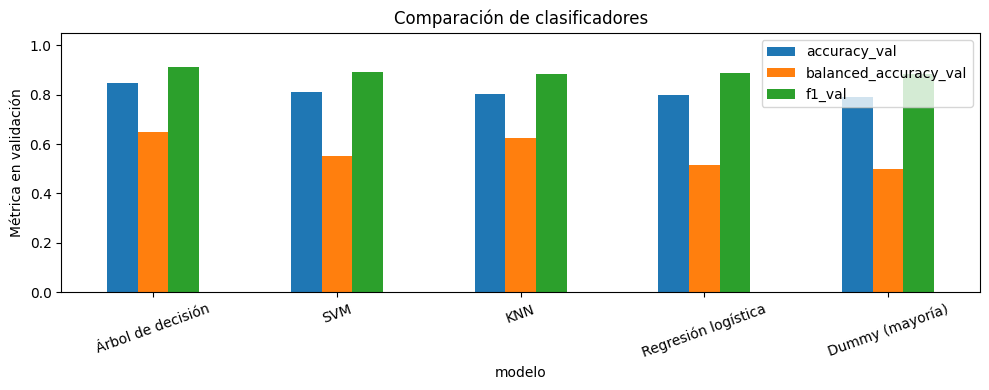

Modelo final elegido sin consultar prueba: Árbol de decisión


In [10]:
# Comparar modelos de clasificación con las mismas particiones y métricas.
# Dummy es una referencia que predice la clase mayoritaria.
# Para los otros algoritmos se usan configuraciones sencillas fijadas a priori.
modelos = {
    "SVM": svm_elegido,
    "Regresión logística": pipeline(LogisticRegression(max_iter=2000, random_state=SEMILLA)),
    "KNN": pipeline(KNeighborsClassifier(n_neighbors=5)),
    "Árbol de decisión": pipeline(DecisionTreeClassifier(max_depth=5, random_state=SEMILLA)),
    "Dummy (mayoría)": pipeline(DummyClassifier(strategy="most_frequent"))
}
comparacion = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred_train = modelo.predict(X_train)
    pred_val = modelo.predict(X_val)
    comparacion.append({"modelo": nombre, "accuracy_train": accuracy_score(y_train, pred_train),
                       **{f"{k}_val": v for k,v in metricas(y_val, pred_val).items()}})
comparacion = pd.DataFrame(comparacion).sort_values(
    ["accuracy_val", "balanced_accuracy_val"], ascending=False, kind="stable").reset_index(drop=True)
display(comparacion.round(4))
ax = comparacion.set_index("modelo")[["accuracy_val", "balanced_accuracy_val", "f1_val"]].plot.bar(
    figsize=(10,4), rot=20)
ax.set(ylabel="Métrica en validación", ylim=(0,1.05), title="Comparación de clasificadores")
plt.tight_layout(); plt.show()
# La referencia Dummy no se considera un candidato productivo.
nombre_final = comparacion.loc[comparacion.modelo.ne("Dummy (mayoría)"), "modelo"].iloc[0]
print("Modelo final elegido sin consultar prueba:", nombre_final)

### Reajuste y evaluación final (una sola vez)

El SVM se reajustaría junto con su preprocesamiento si resulta ganador de la comparación. Si otro algoritmo obtiene mejor validación, se selecciona ese algoritmo. El conjunto de prueba se abre una sola vez para evaluar el modelo elegido, no para volver a elegir parámetros. Se muestra también el resultado de validación del SVM aunque no sea el ganador.

Modelo final: Árbol de decisión


,accuracy,precision,recall,f1,balanced_accuracy
Prueba,0.8058,0.8168,0.9727,0.888,0.5726


              precision    recall  f1-score   support

   No cumple       0.62      0.17      0.27        29
      Cumple       0.82      0.97      0.89       110

    accuracy                           0.81       139
   macro avg       0.72      0.57      0.58       139
weighted avg       0.78      0.81      0.76       139



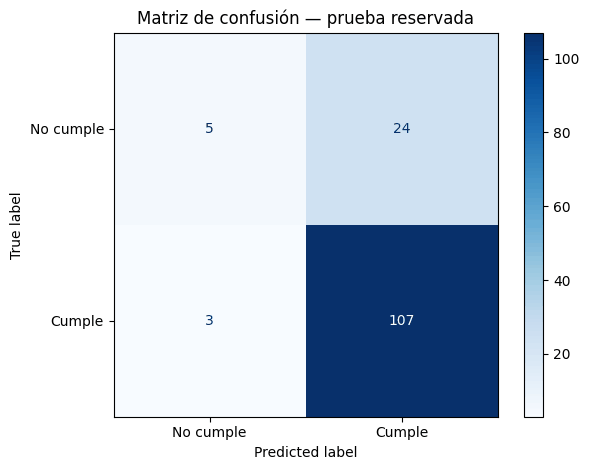

VN=5; FP=24; FN=3; VP=107
El modelo detectó 5 incumplimientos y clasificó 24 incumplimientos como cumplimientos.
Accuracy del SVM en validación: 0.8116
Accuracy final en prueba: 0.8058
Balanced accuracy en prueba: 0.5726


In [11]:
# Reajustar el modelo ganador con entrenamiento + validación.
X_final = pd.concat([X_train, X_val])
y_final = pd.concat([y_train, y_val])
modelo_final = clone(modelos[nombre_final])
modelo_final.fit(X_final, y_final)

# Única predicción sobre prueba reservada, reutilizada para todas las métricas.
y_pred = modelo_final.predict(X_test)
resultado_prueba = metricas(y_test, y_pred)
print("Modelo final:", nombre_final)
display(pd.DataFrame([resultado_prueba], index=["Prueba"]).round(4))
print(classification_report(y_test, y_pred, labels=[0,1],
      target_names=["No cumple", "Cumple"], zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=[0,1])
ConfusionMatrixDisplay(cm, display_labels=["No cumple", "Cumple"]).plot(cmap="Blues")
plt.title("Matriz de confusión — prueba reservada"); plt.tight_layout(); plt.show()
VN, FP, FN, VP = cm.ravel()
print(f"VN={VN}; FP={FP}; FN={FN}; VP={VP}")
print(f"El modelo detectó {VN} incumplimientos y clasificó {FP} incumplimientos como cumplimientos.")
print(f"Accuracy del SVM en validación: {mejor_svm.accuracy_val:.4f}")
print(f"Accuracy final en prueba: {resultado_prueba['accuracy']:.4f}")
print(f"Balanced accuracy en prueba: {resultado_prueba['balanced_accuracy']:.4f}")
assert cm.sum() == len(X_test)

### Conclusiones

- SVM busca una frontera de decisión de margen amplio; cambiar el kernel, C y gamma modifica su capacidad de ajustar los patrones. La selección debe basarse en validación y no en la exactitud de entrenamiento.
- La clase positiva es cumplir la meta. Un falso positivo es un equipo que no cumplió, pero el modelo predijo que sí; por eso conviene revisar la matriz de confusión y el recall de la clase negativa, además de accuracy.
- El objetivo es una clasificación exploratoria de registros de costura, no una predicción causal. Se excluyeron variables potencialmente reveladoras y se ajustó la imputación y el escalado sin acceso a prueba. Si `over_time` se conoce únicamente al cierre, el modelo no debe presentarse como pronóstico anticipado; para ese uso habría que excluirla o verificar su disponibilidad.
- La comparación usa una partición aleatoria estratificada; registros del mismo equipo o fechas próximas pueden aparecer en diferentes conjuntos. Para medir generalización a equipos o fechas nuevas convendría una validación agrupada o temporal. Los modelos alternativos son referencias sencillas, no búsquedas exhaustivas de hiperparámetros.

**Nota de reproducibilidad:** se verificó localmente el flujo analítico con los cuatro predictores y la etiqueta derivada de las 691 filas de costura obtenidas del CSV en GitHub. El enlace RAW se conserva para repetir la carga original en Colab. El entorno local no pudo acceder directamente a esa URL; no se afirma que se haya ejecutado en una sesión de Colab.

**Resultados observados:** el mejor SVM utiliza RBF, C=1 y gamma=0.1 (accuracy de validación 81.16%; balanced accuracy 55.17%). El árbol de decisión obtuvo la mejor validación y fue el único modelo evaluado en prueba: accuracy 80.58%, balanced accuracy 57.26%. Detectó solo 5 de 29 incumplimientos (recall negativo 17.24%), por lo que el rendimiento no es suficiente para identificar incumplimientos de forma fiable. El desequilibrio de clases explica por qué una exactitud cercana al 80% no basta para afirmar que el modelo es bueno.

**Lectura de las regiones de decisión:** la proyección PCA retiene solo una parte de la información. La superposición de las clases y el posible predominio de la clase que cumple deben interpretarse junto con la matriz de confusión; los círculos muestran los vectores de soporte de cada modelo bidimensional, no los del modelo de cuatro variables.